## The Data

At this link, you will find a dataset containing information about heart disease patients: https://www.dropbox.com/scl/fi/0vrpdnq5asmeulc4gd50y/ha_1.csv?rlkey=ciisalceotl77ffqhqe3kujzv&dl=1

A description of the original dataset can be found here: https://archive.ics.uci.edu/dataset/45/heart+disease (However, this dataset has been cleaned and reduced, and the people have been given fictious names.)

## 1. Logistic Regression

Fit a Logistic Regression using only `age` and `chol` (cholesterol) as predictors.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

How high for the doctors to estimate a 90% chance that heart disease is present?

In [1]:
import pandas as pd
import numpy as np

ha = pd.read_csv("https://www.dropbox.com/scl/fi/0vrpdnq5asmeulc4gd50y/ha_1.csv?rlkey=ciisalceotl77ffqhqe3kujzv&dl=1")
ha.head()

,Name,age,sex,cp,trtbps,chol,restecg,thalach,diagnosis
0,Magnolia Cassin,60,1,1,117,230,1,160,No Disease
1,Dr. Cathern Heathcote,60,0,3,102,318,1,160,Disease
2,Miles Wolf,62,0,3,130,263,1,97,No Disease
3,Mikaila Block,43,1,1,115,303,1,181,Disease
4,Mrs. Jacquline Marquardt,66,1,1,120,302,0,151,Disease


In [4]:
ha["diagnosis"].value_counts()

diagnosis
Disease       115
No Disease     89
Name: count, dtype: int64

In [5]:
ha["disease_flag"] = (ha["diagnosis"] == "Disease").astype(int)
ha["disease_flag"].value_counts()

disease_flag
1    115
0     89
Name: count, dtype: int64

In [6]:
from sklearn.linear_model import LogisticRegression

X = ha[["age", "chol"]]
y = ha["disease_flag"]

log_reg = LogisticRegression()
log_reg.fit(X, y)

b0 = log_reg.intercept_[0]
b_age, b_chol = log_reg.coef_[0]
print("intercept:", b0, "| age coef:", b_age, "| chol coef:", b_chol)

intercept: 3.2401122588587326 | age coef: -0.046863306130359 | chol coef: -0.0018012385190294068


In [7]:
age_value = 55

chol_for_50 = (0 - b0 - b_age * age_value) / b_chol
chol_for_90 = (np.log(0.9 / 0.1) - b0 - b_age * age_value) / b_chol

print("Cholesterol for predicted disease present (50% cutoff):", round(chol_for_50, 1))
print("Cholesterol for 90% estimated probability of disease:", round(chol_for_90, 1))

Cholesterol for predicted disease present (50% cutoff): 367.9
Cholesterol for 90% estimated probability of disease: -852.0


Cholesterol needs to be below about 368 (not above) for the model to predict disease present at age 55. 

There’s no cholesterol level, however low, that gets the model to 90% confidence at that age.

## 2. Linear Discriminant Analysis

Fit an LDA model using only `age` and `chol` (cholesterol)  as predictors.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

In [8]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis()
lda.fit(X, y)

lda_b0 = lda.intercept_[0]
lda_b_age, lda_b_chol = lda.coef_[0]
print("intercept:", lda_b0, "| age coef:", lda_b_age, "| chol coef:", lda_b_chol)

intercept: 3.219677660406875 | age coef: -0.046557435536944775 | chol coef: -0.0017896671039291305


In [9]:
chol_boundary_lda = (0 - lda_b0 - lda_b_age * age_value) / lda_b_chol
print("LDA cholesterol boundary at age 55:", round(chol_boundary_lda, 1))

LDA cholesterol boundary at age 55: 368.2


The model predicts disease present when cholesterol is below 368.2, consistent with what we saw before.

## 3. Support Vector Classifier

Fit an SVC model using only `age` and `chol` as predictors.  Don't forget to tune the regularization parameter.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

In [10]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

svc_pipeline = SVC(kernel="linear")
param_grid_svc = {"C": np.logspace(-3, 3, 13)}

gscv_svc = GridSearchCV(svc_pipeline, param_grid_svc, cv=10, scoring="accuracy")
gscv_svc.fit(X, y)

print("best C:", gscv_svc.best_params_)
print("best CV accuracy:", round(gscv_svc.best_score_, 3))

best C: {'C': np.float64(0.01)}
best CV accuracy: 0.603


In [11]:
b0 = gscv_svc.best_estimator_.intercept_[0]
b_age, b_chol = gscv_svc.best_estimator_.coef_[0]

chol_boundary_svc = (0 - b0 - b_age * age_value) / b_chol
print("SVC cholesterol boundary at age 55:", round(chol_boundary_svc, 1))

SVC cholesterol boundary at age 55: 312.7


At age 55, the SVC model predicts heart disease is present when cholesterol is below about 312.7 mg/dL. Same direction as logistic regression and LDA, where higher cholesterol was associated with lower predicted disease probability in this dataset, but the SVC’s threshold (312.7) is noticeably lower than the logistic regression and LDA thresholds (around 368).

## 4. Comparing Decision Boundaries

Make a scatterplot of `age` and `chol`, coloring the points by their true disease outcome.  Add a line to the plot representing the **linear separator** (aka **decision boundary**) for each of the three models above.

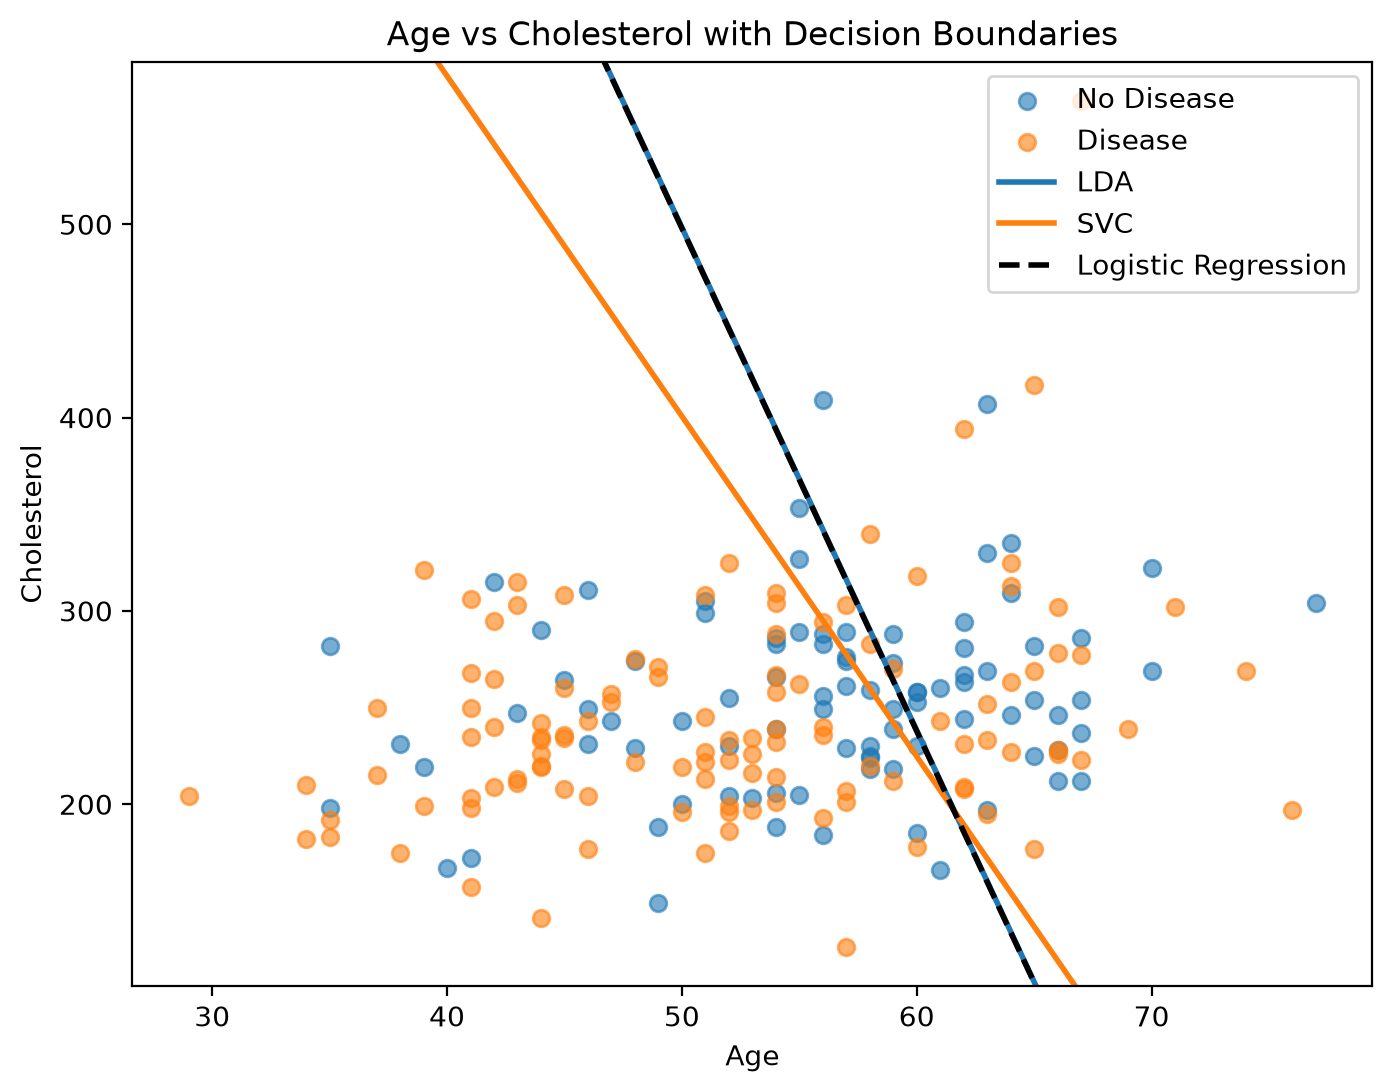

In [15]:
import matplotlib.pyplot as plt
import numpy as np

lr_b0 = log_reg.intercept_[0]
lr_b_age, lr_b_chol = log_reg.coef_[0]

svc_b0 = gscv_svc.best_estimator_.intercept_[0]
svc_b_age, svc_b_chol = gscv_svc.best_estimator_.coef_[0]

age_range = np.linspace(ha["age"].min(), ha["age"].max(), 100)

lr_boundary = -(lr_b0 + lr_b_age * age_range) / lr_b_chol
lda_boundary = -(lda_b0 + lda_b_age * age_range) / lda_b_chol
svc_boundary = -(svc_b0 + svc_b_age * age_range) / svc_b_chol

plt.figure(figsize=(8, 6))

plt.scatter(ha.loc[ha["disease_flag"] == 0, "age"], ha.loc[ha["disease_flag"] == 0, "chol"],
            label="No Disease", alpha=0.6)
plt.scatter(ha.loc[ha["disease_flag"] == 1, "age"], ha.loc[ha["disease_flag"] == 1, "chol"],
            label="Disease", alpha=0.6)

plt.plot(age_range, lda_boundary, label="LDA", linewidth=2)
plt.plot(age_range, svc_boundary, label="SVC", linewidth=2)
plt.plot(age_range, lr_boundary, label="Logistic Regression", linewidth=2, linestyle="--", color="black")

plt.xlabel("Age")
plt.ylabel("Cholesterol")
plt.ylim(ha["chol"].min() - 20, ha["chol"].max() + 20)
plt.legend()
plt.title("Age vs Cholesterol with Decision Boundaries")
plt.show()